
# Bike Rental Prediction Using Machine Learning

## 1. Project Introduction

Bike-sharing systems provide an automated method of renting bicycles for transportation.

The objective of this project is to perform exploratory data analysis and develop machine learning regression models to predict daily bike rental demand based on environmental, seasonal and calendar-related information.

## 2. Project Objectives

1. Perform complete exploratory data analysis.
2. Understand factors affecting bike rental demand.
3. Identify missing values, duplicates and outliers.
4. Perform feature engineering and data preprocessing.
5. Build multiple regression models.
6. Compare model performance.
7. Perform cross-validation and hyperparameter tuning.
8. Recommend the best-performing model.
9. Document challenges and solutions.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [3]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Daily Dataset Shape:", day_df.shape)
print("Hourly Dataset Shape:", hour_df.shape)

Daily Dataset Shape: (731, 16)
Hourly Dataset Shape: (17379, 17)


In [4]:
print(day_df.head())
print(hour_df.head())

   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  
   instant      dteday  se

In [5]:
print(day_df.tail())
print(hour_df.tail())

     instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
726      727  2012-12-27       1   1    12        0        4           1   
727      728  2012-12-28       1   1    12        0        5           1   
728      729  2012-12-29       1   1    12        0        6           0   
729      730  2012-12-30       1   1    12        0        0           0   
730      731  2012-12-31       1   1    12        0        1           1   

     weathersit      temp     atemp       hum  windspeed  casual  registered  \
726           2  0.254167  0.226642  0.652917   0.350133     247        1867   
727           2  0.253333  0.255046  0.590000   0.155471     644        2451   
728           2  0.253333  0.242400  0.752917   0.124383     159        1182   
729           1  0.255833  0.231700  0.483333   0.350754     364        1432   
730           2  0.215833  0.223487  0.577500   0.154846     439        2290   

      cnt  
726  2114  
727  3095  
728  1341  
729  1796  
73

In [6]:
print("DAILY DATASET INFORMATION")
day_df.info()

print("\nHOURLY DATASET INFORMATION")
hour_df.info()

DAILY DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

HOURLY DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
R

In [7]:
print("Daily Columns:")
print(day_df.columns.tolist())

print("\nHourly Columns:")
print(hour_df.columns.tolist())

Daily Columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Hourly Columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [8]:
print("Daily Missing Values:")
print(day_df.isnull().sum())

print("\nHourly Missing Values:")
print(hour_df.isnull().sum())

Daily Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Hourly Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [9]:
missing = pd.DataFrame({
    'Missing Count': day_df.isnull().sum(),
    'Missing Percentage': day_df.isnull().mean() * 100
})

print(missing.sort_values(
    by='Missing Percentage',
    ascending=False
))

            Missing Count  Missing Percentage
instant                 0                 0.0
dteday                  0                 0.0
season                  0                 0.0
yr                      0                 0.0
mnth                    0                 0.0
holiday                 0                 0.0
weekday                 0                 0.0
workingday              0                 0.0
weathersit              0                 0.0
temp                    0                 0.0
atemp                   0                 0.0
hum                     0                 0.0
windspeed               0                 0.0
casual                  0                 0.0
registered              0                 0.0
cnt                     0                 0.0


In [10]:
print("Daily Duplicates:", day_df.duplicated().sum())
print("Hourly Duplicates:", hour_df.duplicated().sum())

Daily Duplicates: 0
Hourly Duplicates: 0


In [11]:
print(day_df.describe().T)

            count         mean          std        min          25%  \
instant     731.0   366.000000   211.165812   1.000000   183.500000   
season      731.0     2.496580     1.110807   1.000000     2.000000   
yr          731.0     0.500684     0.500342   0.000000     0.000000   
mnth        731.0     6.519836     3.451913   1.000000     4.000000   
holiday     731.0     0.028728     0.167155   0.000000     0.000000   
weekday     731.0     2.997264     2.004787   0.000000     1.000000   
workingday  731.0     0.683995     0.465233   0.000000     0.000000   
weathersit  731.0     1.395349     0.544894   1.000000     1.000000   
temp        731.0     0.495385     0.183051   0.059130     0.337083   
atemp       731.0     0.474354     0.162961   0.079070     0.337842   
hum         731.0     0.627894     0.142429   0.000000     0.520000   
windspeed   731.0     0.190486     0.077498   0.022392     0.134950   
casual      731.0   848.176471   686.622488   2.000000   315.500000   
regist

In [12]:
for col in day_df.columns:
    print(f"\n{col}:")
    print(day_df[col].nunique())


instant:
731

dteday:
731

season:
4

yr:
2

mnth:
12

holiday:
2

weekday:
7

workingday:
2

weathersit:
3

temp:
499

atemp:
690

hum:
595

windspeed:
650

casual:
606

registered:
679

cnt:
696


In [13]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print(day_df.dtypes)

instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object


In [14]:
print("Target Variable: cnt")

print("Mean:", day_df['cnt'].mean())
print("Median:", day_df['cnt'].median())
print("Minimum:", day_df['cnt'].min())
print("Maximum:", day_df['cnt'].max())

Target Variable: cnt
Mean: 4504.3488372093025
Median: 4548.0
Minimum: 22
Maximum: 8714


**Insight:**

The distribution of daily bike rentals shows how rental demand varies across different days. Most observations are concentrated around the central rental range, while some days experience significantly higher or lower demand. This indicates that bike rental demand varies depending on seasonal, environmental and calendar-related factors.

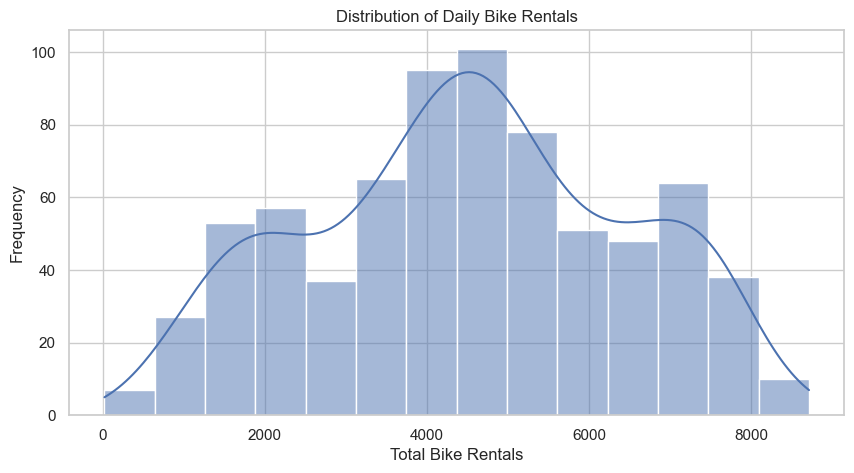

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(data=day_df, x='cnt', kde=True)

plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.show()

**Insight:**

The boxplot identifies unusually high and low daily rental counts. These values may represent days with exceptional demand or reduced demand due to external conditions. Such observations should not automatically be removed because they may contain important information about actual rental behavior.

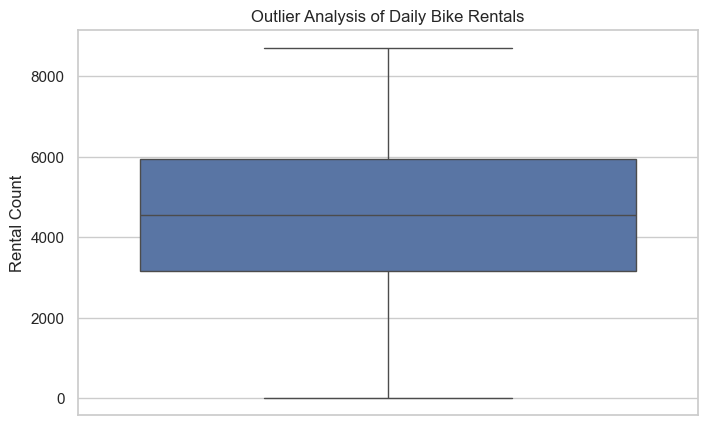

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=day_df['cnt'])

plt.title("Outlier Analysis of Daily Bike Rentals")
plt.ylabel("Rental Count")
plt.show()

**Insight:**

The numerical variable distributions show that temperature, feeling temperature, humidity and windspeed have different patterns and ranges. The rental count distribution also indicates variations in daily demand. These distributions help identify skewness and understand the characteristics of numerical features before model training.

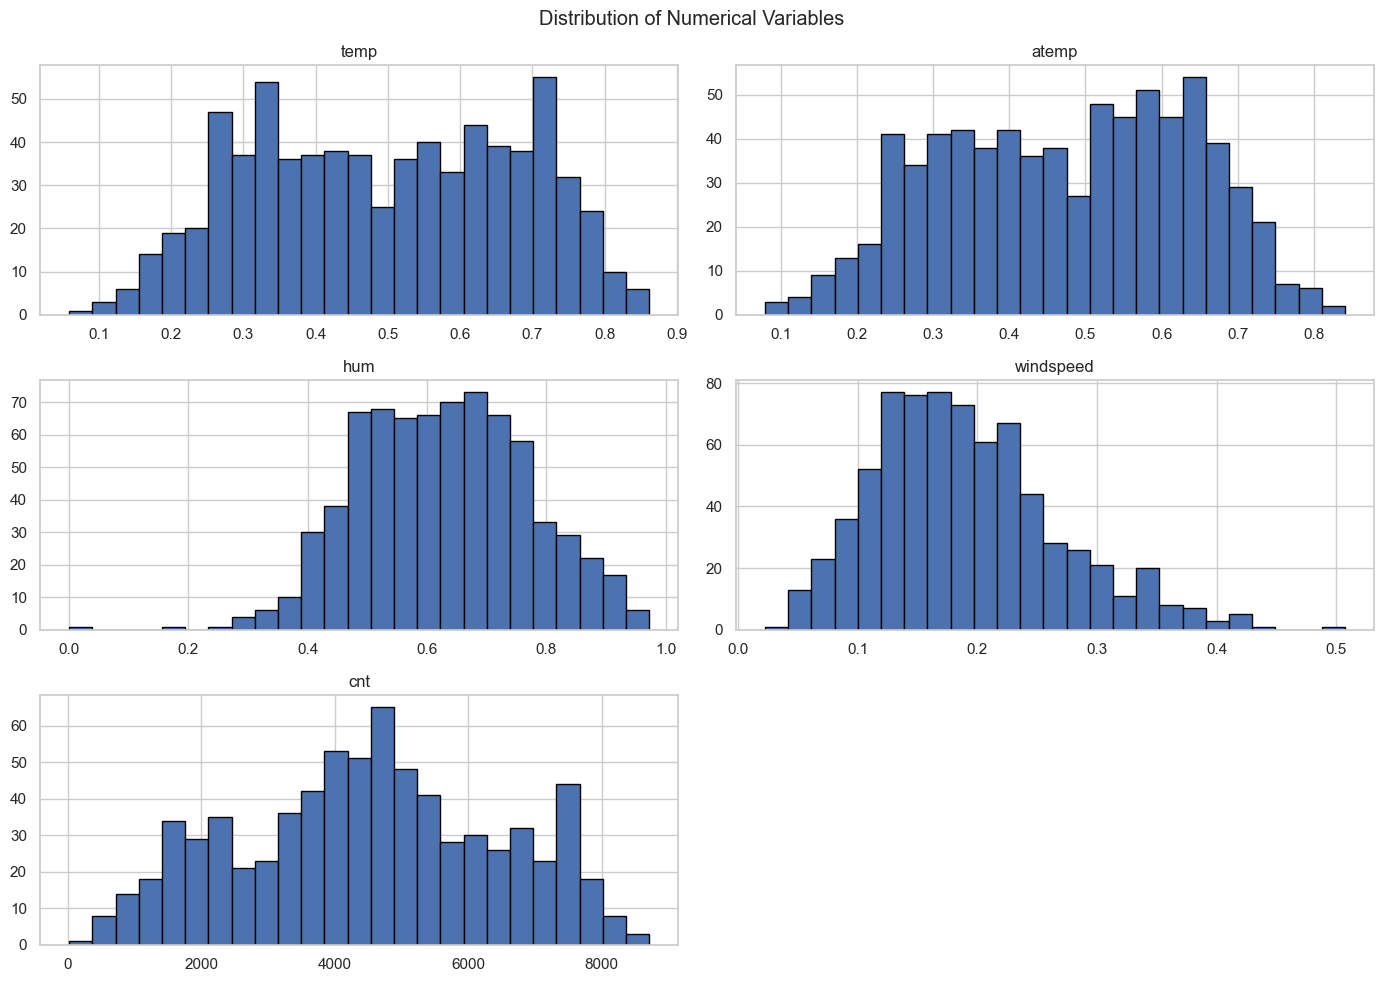

In [17]:
numerical_cols = [
    'temp', 'atemp', 'hum', 'windspeed', 'cnt'
]

day_df[numerical_cols].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

**Insight:**

The categorical distributions show how observations are distributed across seasons, months, weekdays, holidays, working days and weather conditions. Understanding these distributions helps identify category imbalances and the frequency of different environmental and calendar conditions in the dataset.

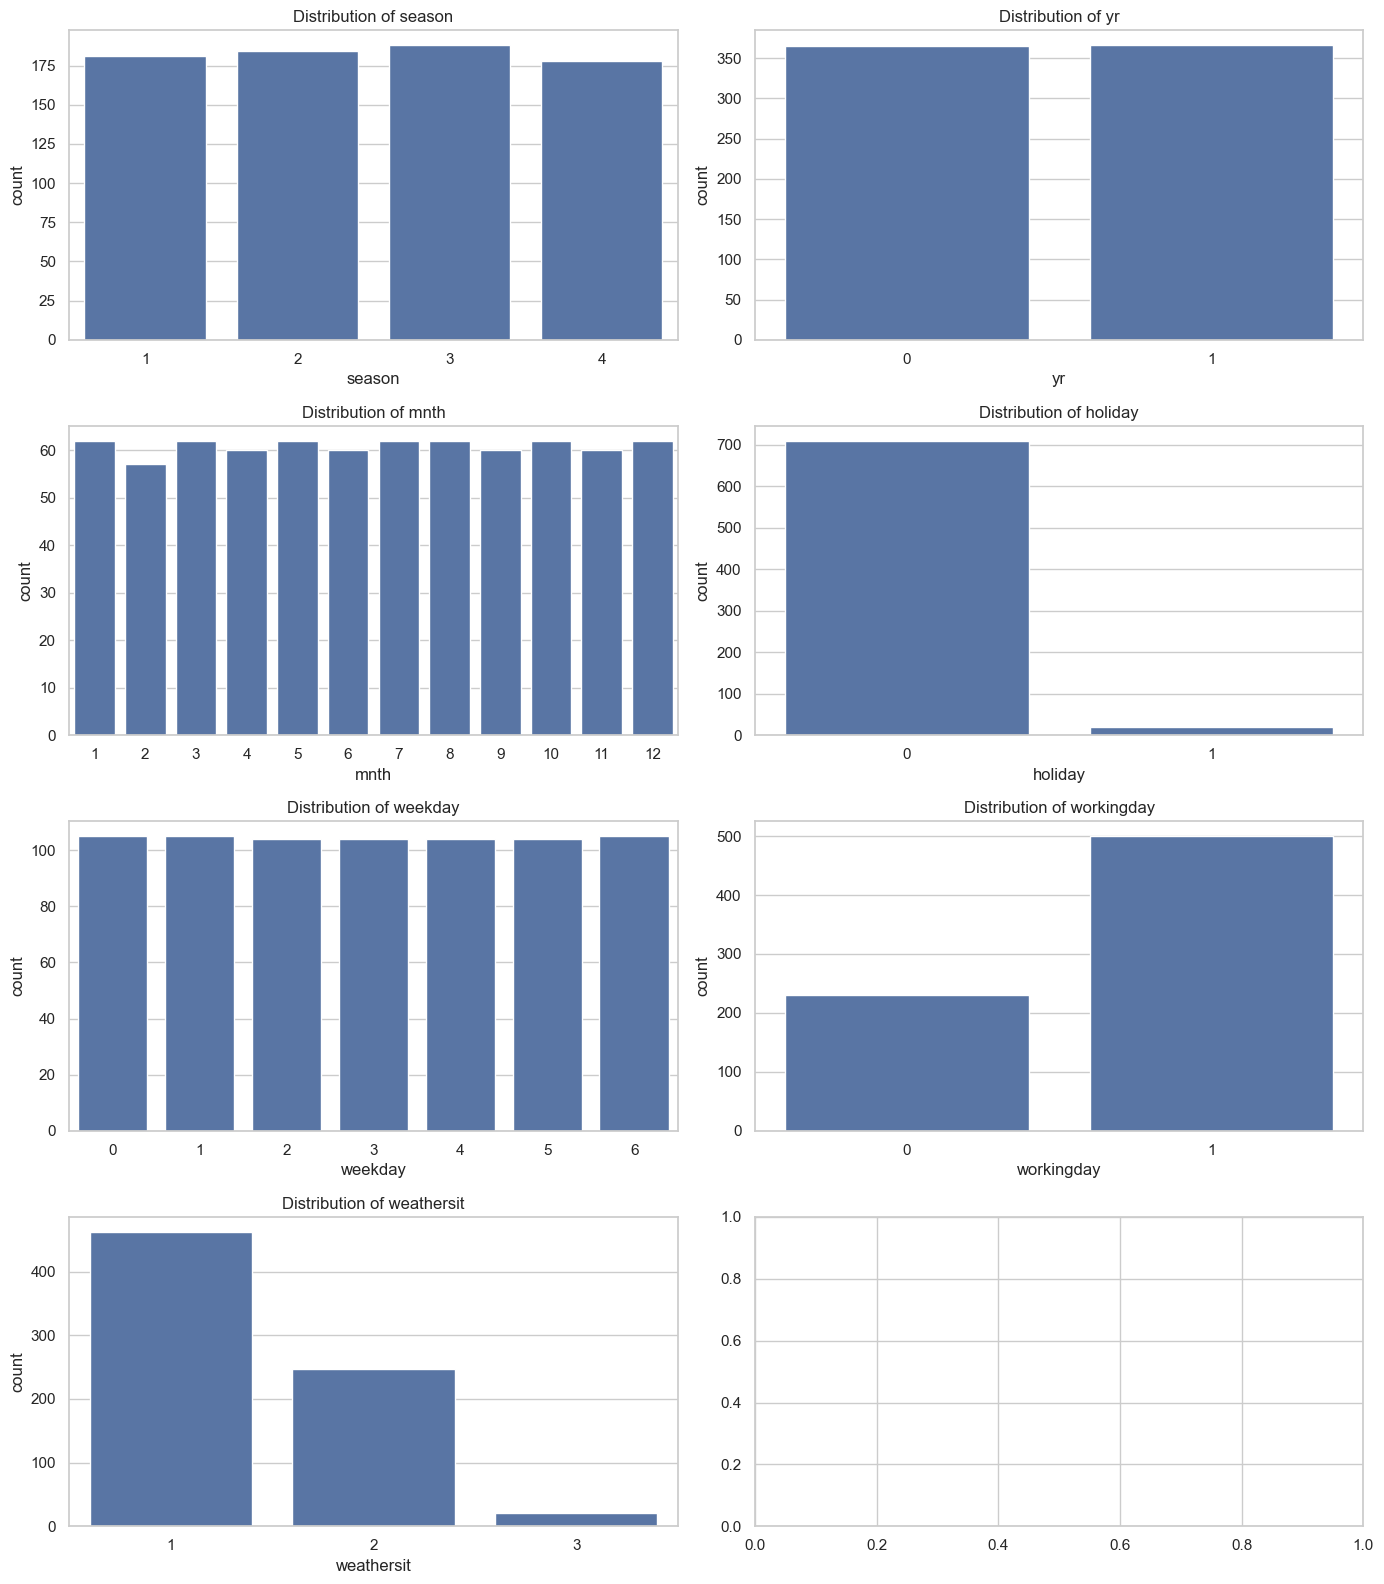

In [18]:
categorical_cols = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=day_df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

**Insight:**

The analysis shows that bike rental demand varies across seasons. Summer (Season 2) and Fall (Season 3) have higher average rentals, while Spring (Season 1) has the lowest average demand. Fall records the highest average rental count of approximately 5,644 bikes, indicating that seasonal conditions influence customer demand.

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


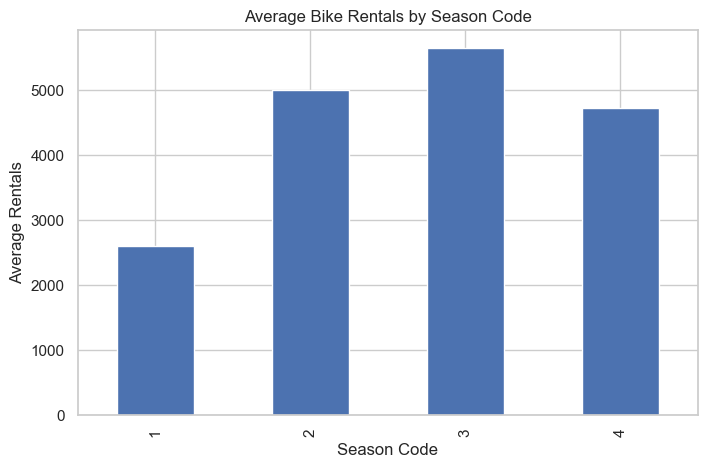

In [19]:
season_rentals = day_df.groupby('season')['cnt'].mean()

print(season_rentals)

season_rentals.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Average Bike Rentals by Season Code")
plt.xlabel("Season Code")
plt.ylabel("Average Rentals")
plt.show()

**Insight:**

Monthly rental demand varies throughout the year. Demand generally increases during warmer months, reaches higher levels during the summer and early autumn period, and decreases during colder months. This indicates a seasonal pattern in bike rental usage.

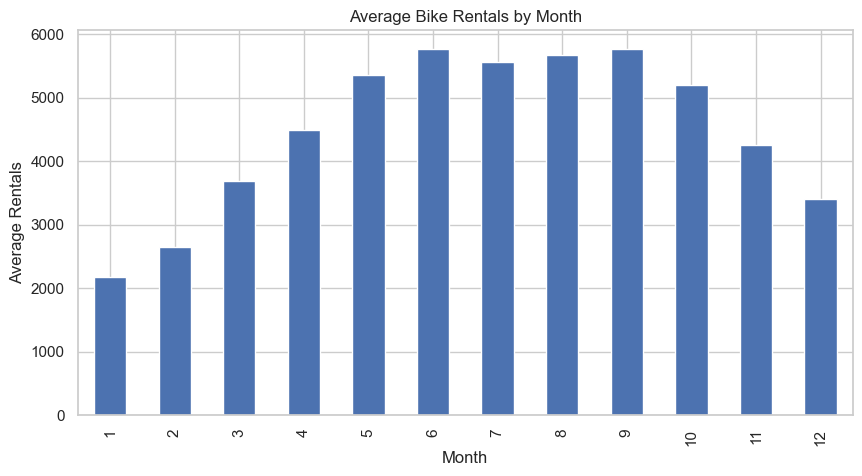

In [20]:
monthly_rentals = day_df.groupby('mnth')['cnt'].mean()

monthly_rentals.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.show()

**Insight:**

The boxplot compares bike rental demand on working and non-working days. The distribution indicates differences in rental behavior between the two categories. Working days may reflect regular commuting demand, while non-working days may involve recreational usage. The comparison helps understand the influence of daily schedules on bike rentals.

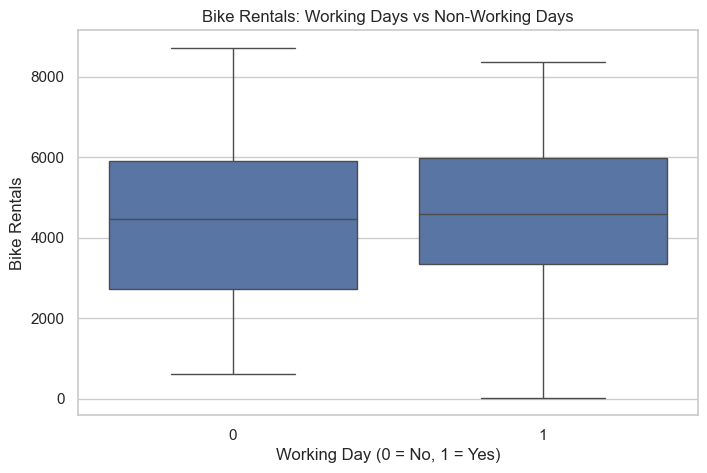

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=day_df,
    x='workingday',
    y='cnt'
)

plt.title("Bike Rentals: Working Days vs Non-Working Days")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Bike Rentals")
plt.show()

**Insight:**

Bike rental demand changes across different weather situations. Favorable weather conditions generally encourage more people to use rental bicycles, whereas adverse weather conditions reduce demand. This demonstrates that weather is an important factor influencing bike rental behavior.

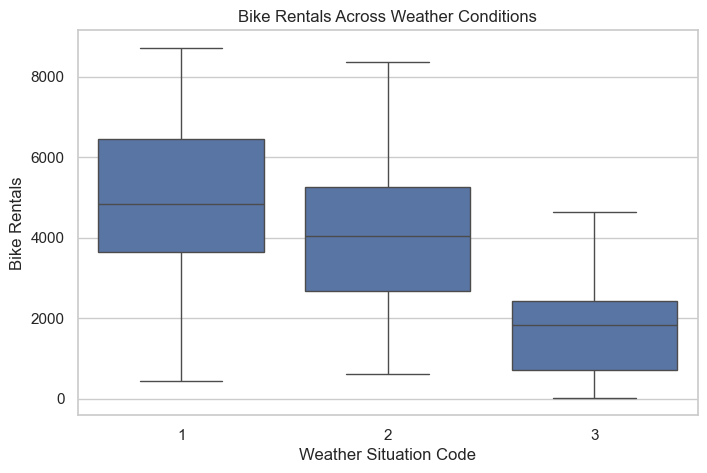

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=day_df,
    x='weathersit',
    y='cnt'
)

plt.title("Bike Rentals Across Weather Conditions")
plt.xlabel("Weather Situation Code")
plt.ylabel("Bike Rentals")
plt.show()

**Insight:**

The scatterplot indicates a positive relationship between temperature and bike rental demand. As temperature increases, the number of rentals generally increases. This suggests that comfortable and warmer weather conditions encourage bicycle usage.

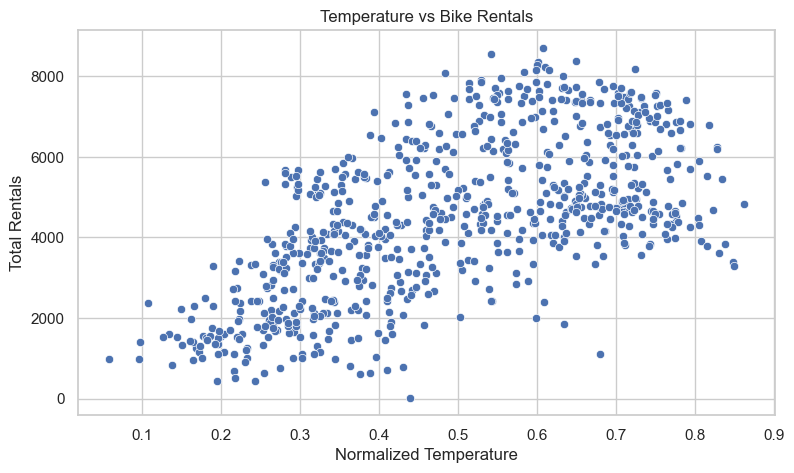

In [23]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=day_df,
    x='temp',
    y='cnt'
)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Rentals")
plt.show()

**Insight:**

The scatterplot shows a generally negative relationship between humidity and bike rental demand. Higher humidity levels can make outdoor activities less comfortable, potentially reducing bicycle usage. However, other environmental and seasonal factors also influence demand.

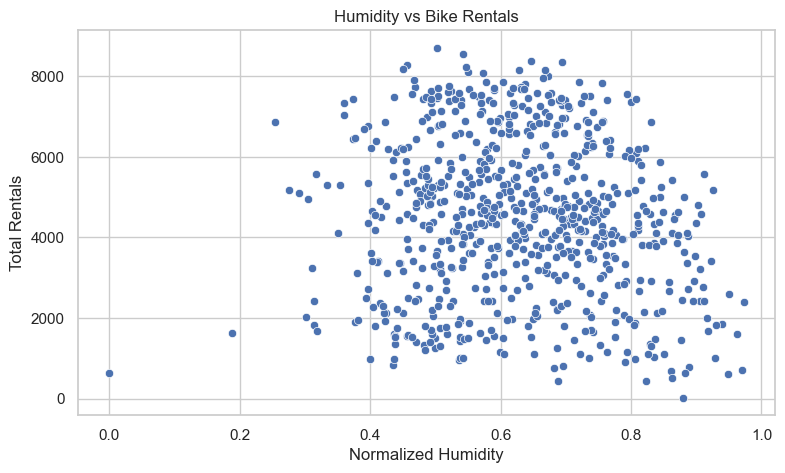

In [24]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=day_df,
    x='hum',
    y='cnt'
)

plt.title("Humidity vs Bike Rentals")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total Rentals")
plt.show()

**Insight:**

The scatterplot indicates that windspeed can influence bike rental demand. Higher windspeed may discourage bicycle usage because riding becomes less comfortable. However, the relationship is not necessarily linear, and other factors also contribute to rental variations.

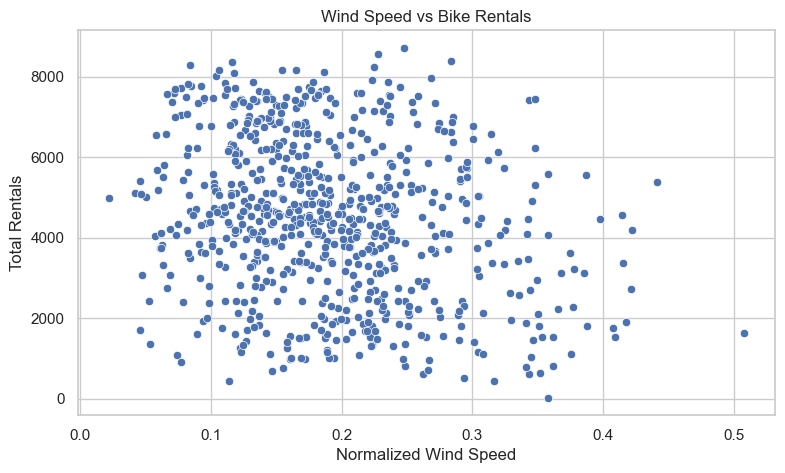

In [25]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=day_df,
    x='windspeed',
    y='cnt'
)

plt.title("Wind Speed vs Bike Rentals")
plt.xlabel("Normalized Wind Speed")
plt.ylabel("Total Rentals")
plt.show()

**Insight:**

Hourly analysis reveals that bike rental demand varies significantly throughout the day. Rental activity generally increases during morning and evening commuting periods, with lower activity during late-night and early-morning hours. This indicates that time of day plays an important role in determining bike rental demand.

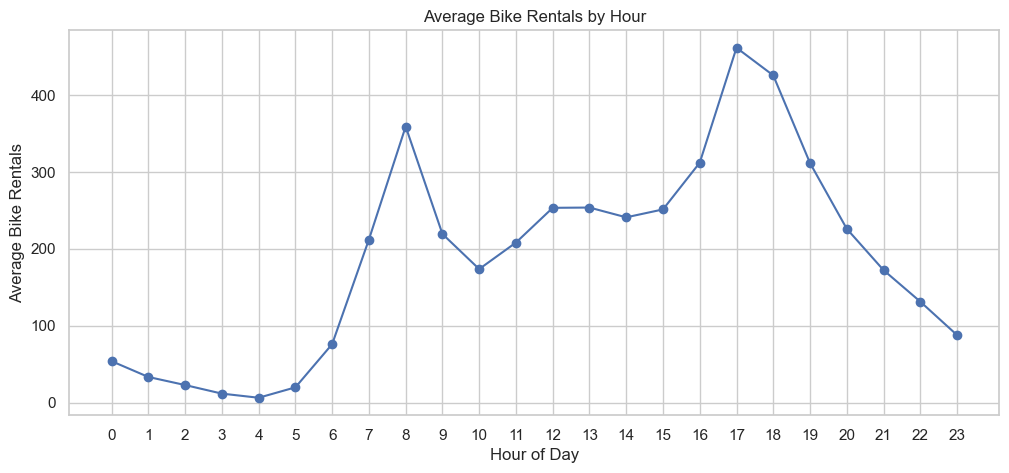

In [26]:
hourly_rentals = hour_df.groupby('hr')['cnt'].mean()

hourly_rentals.plot(
    figsize=(12, 5),
    marker='o'
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(24))
plt.show()

**Insight:**

Working days generally show distinct morning and evening rental peaks associated with commuting activities. Non-working days exhibit a different demand pattern, with rentals distributed more broadly across daytime hours. This indicates that user behavior differs depending on whether the day is a working day or a holiday.

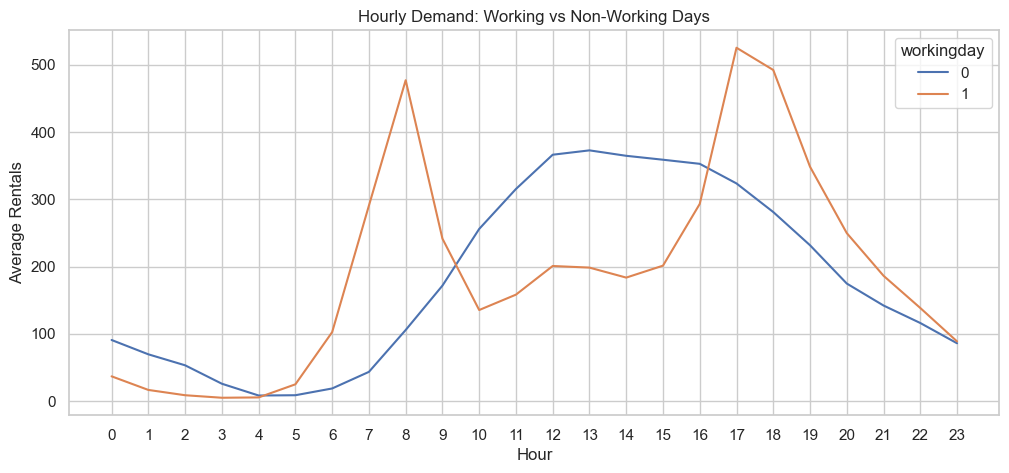

In [27]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_df,
    x='hr',
    y='cnt',
    hue='workingday',
    estimator='mean',
    errorbar=None
)

plt.title("Hourly Demand: Working vs Non-Working Days")
plt.xlabel("Hour")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.show()

**Insight:**

The correlation heatmap helps identify relationships between numerical variables. Temperature and feeling temperature are strongly positively correlated, while rental count has a positive relationship with temperature and a negative relationship with some unfavorable weather variables. The heatmap also helps identify multicollinearity between input features before model development. Correlation does not necessarily imply causation.

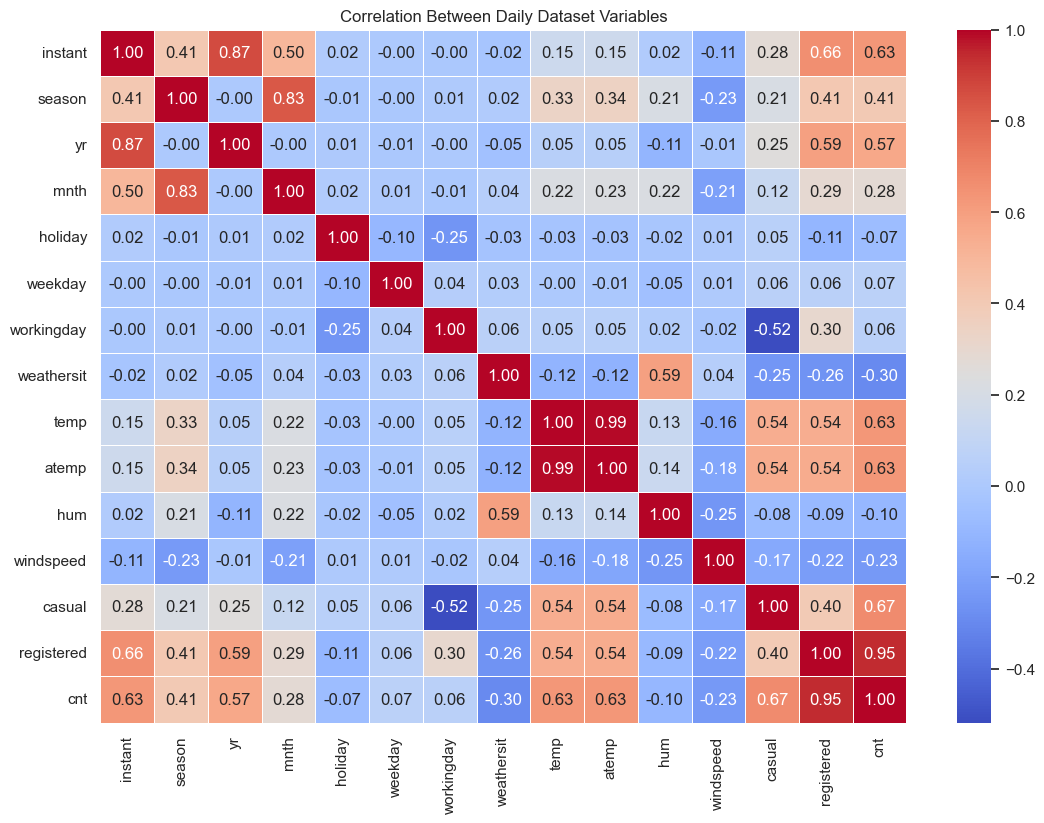

In [28]:
plt.figure(figsize=(13, 9))

corr = day_df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Between Daily Dataset Variables")
plt.show()

**Insight:**

The boxplots identify potential outliers in temperature, feeling temperature, humidity, windspeed and rental count. These observations are useful for understanding data variability. Outliers are retained unless there is evidence that they represent incorrect or invalid records, because genuine extreme conditions can influence rental demand.

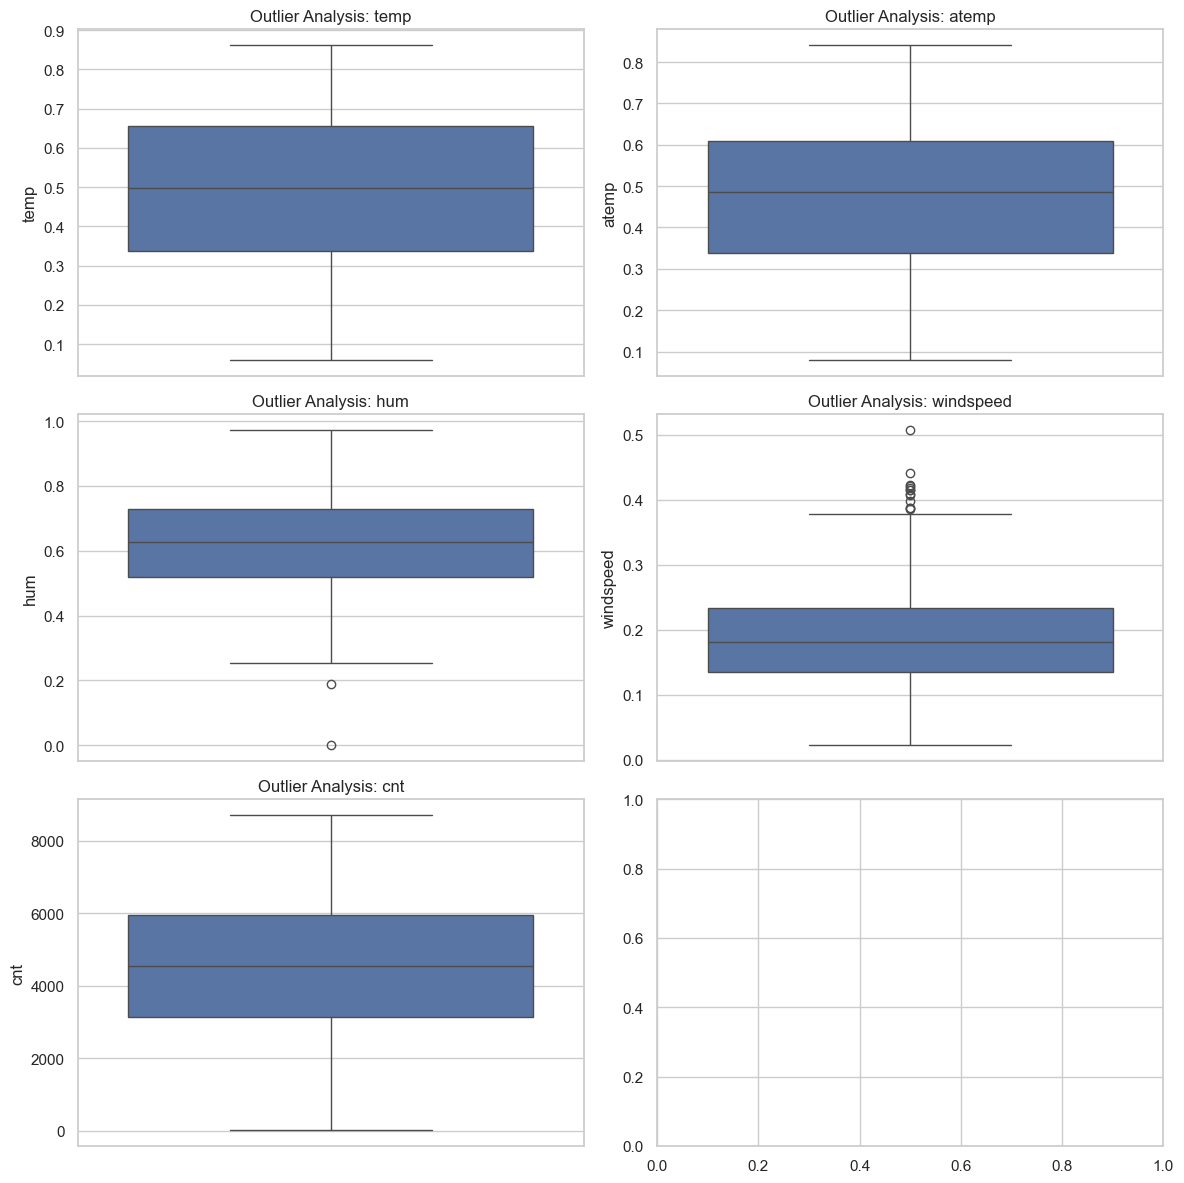

In [29]:
outlier_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for col, ax in zip(outlier_cols, axes.flatten()):
    sns.boxplot(y=day_df[col], ax=ax)
    ax.set_title(f"Outlier Analysis: {col}")

plt.tight_layout()
plt.show()

**Insight:**

Skewness analysis helps identify asymmetry in numerical distributions. Variables with positive skewness contain a longer right tail, whereas negative skewness indicates a longer left tail. Understanding skewness helps determine whether additional transformations may be useful during preprocessing.

In [30]:
skewness = day_df[
    ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
].skew()

print("Skewness of numerical variables:")
display(skewness.to_frame(name='Skewness'))

Skewness of numerical variables:


,Skewness
temp,-0.054521
atemp,-0.131088
hum,-0.069783
windspeed,0.677345
cnt,-0.047353


In [31]:
day_df['day_of_month'] = day_df['dteday'].dt.day
day_df['day_of_year'] = day_df['dteday'].dt.dayofyear

print(day_df[['dteday', 'day_of_month', 'day_of_year']].head())

      dteday  day_of_month  day_of_year
0 2011-01-01             1            1
1 2011-01-02             2            2
2 2011-01-03             3            3
3 2011-01-04             4            4
4 2011-01-05             5            5


**Insight:**

The scatterplot shows variations in daily rental demand across the days of the year. The pattern suggests that rental activity changes over time due to seasonal and environmental influences. Day-of-year information can provide additional temporal context for predicting bike rental demand.

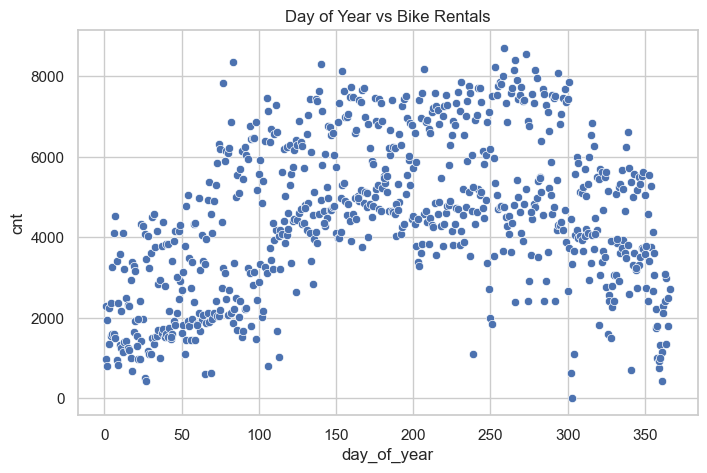

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=day_df,
    x='day_of_year',
    y='cnt'
)

plt.title("Day of Year vs Bike Rentals")
plt.show()

In [33]:
print("Checking target relationship:")

print(
    "Maximum difference:",
    (day_df['cnt'] - (
        day_df['casual'] + day_df['registered']
    )).abs().max()
)

print("\nTarget-related columns:")
print(['casual', 'registered', 'cnt'])

Checking target relationship:
Maximum difference: 0

Target-related columns:
['casual', 'registered', 'cnt']


In [34]:
target = 'cnt'

features = [
    'season',
    'yr',
    'mnth',
    'holiday',
    'weekday',
    'workingday',
    'weathersit',
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'day_of_month',
    'day_of_year'
]

X = day_df[features].copy()
y = day_df[target].copy()

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (731, 13)
Target Shape: (731,)


In [35]:
categorical_features = [
    'season',
    'yr',
    'mnth',
    'holiday',
    'weekday',
    'workingday',
    'weathersit'
]

numerical_features = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'day_of_month',
    'day_of_year'
]

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
Numerical: ['temp', 'atemp', 'hum', 'windspeed', 'day_of_month', 'day_of_year']


In [36]:
day_df = day_df.sort_values('dteday').reset_index(drop=True)

X = day_df[features].copy()
y = day_df['cnt'].copy()

split_index = int(len(day_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (584, 13)
Testing Shape: (147, 13)


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.dummy import DummyRegressor

from sklearn.model_selection import (
    TimeSeriesSplit,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [39]:
baseline = DummyRegressor(strategy='mean')

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 2290.4127061783615
Baseline RMSE: 2560.5558481236217
Baseline R2: -0.8657005548327481


In [40]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

print("Candidate models created:")
print(list(models.keys()))

Candidate models created:
['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [41]:
model_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    model_pipelines[name] = pipeline

print("All model pipelines created.")

All model pipelines created.


In [42]:
for name, pipeline in model_pipelines.items():

    pipeline.fit(X_train, y_train)

    print(name, "trained successfully")

Linear Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


In [43]:
results = []

for name, pipeline in model_pipelines.items():

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

model_results = pd.DataFrame(results)

print(
    model_results.sort_values('RMSE')
)

               Model          MAE         RMSE  R2 Score
3  Gradient Boosting   757.907685   943.685716  0.746587
0  Linear Regression   786.213651  1106.347846  0.651697
2      Random Forest   887.588163  1107.339199  0.651073
1      Decision Tree  1265.435374  1635.147981  0.239170


**Insight:**

The model comparison indicates that Gradient Boosting achieves the lowest test RMSE among the initial candidate models, followed by Linear Regression and Random Forest. Decision Tree produces the highest RMSE. Therefore, Gradient Boosting provides the best initial holdout prediction performance.

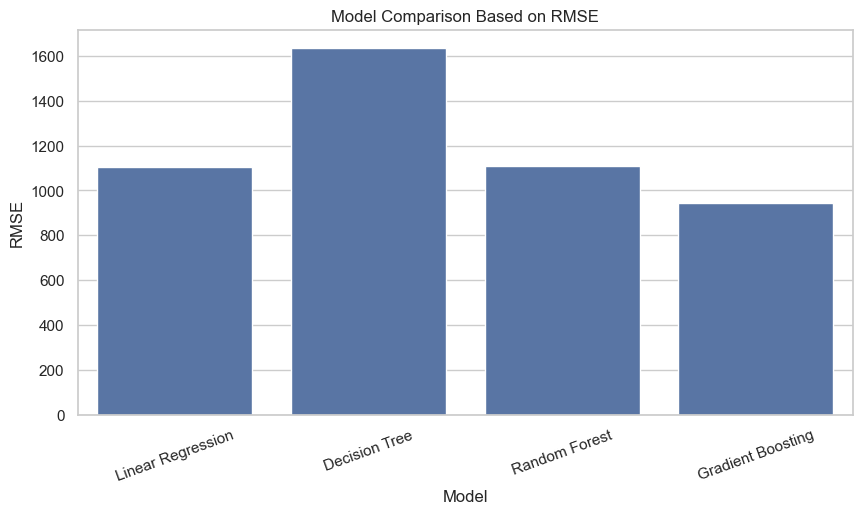

In [44]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x='Model',
    y='RMSE'
)

plt.title("Model Comparison Based on RMSE")
plt.xticks(rotation=20)
plt.show()

In [45]:
tscv = TimeSeriesSplit(n_splits=5)

print("Number of validation splits:", tscv.get_n_splits())

Number of validation splits: 5


In [46]:
cv_results = []

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=tscv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV MAE': -scores['test_MAE'].mean(),
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV R2': scores['test_R2'].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print(
    cv_results_df.sort_values('CV RMSE')
)

               Model       CV MAE      CV RMSE     CV R2
0  Linear Regression   959.792707  1174.020588 -0.536016
3  Gradient Boosting   983.777987  1202.242084 -0.676966
2      Random Forest  1099.137649  1328.076783 -0.836849
1      Decision Tree  1311.410309  1551.312591 -1.493099


**Insight:**

Cross-validation provides a more comprehensive assessment of model performance across multiple chronological validation splits. Linear Regression achieves the lowest average CV RMSE among the initial candidate models. However, the negative average R² values indicate that the models struggle to generalize consistently across the validation periods.

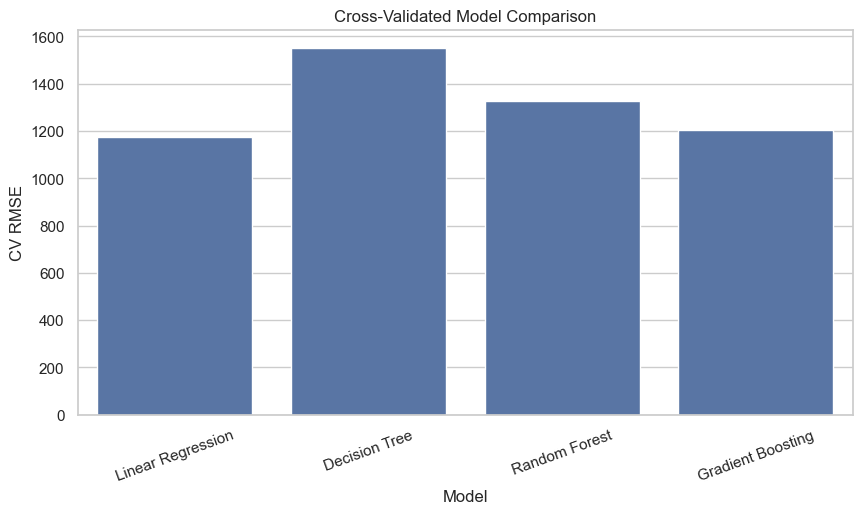

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x='Model',
    y='CV RMSE'
)

plt.title("Cross-Validated Model Comparison")
plt.xticks(rotation=20)
plt.show()

In [48]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [0.7, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 10}

Best CV RMSE:
1315.3717813564767


In [49]:
best_model = random_search.best_estimator_

print("Best tuned model:")
print(best_model)

Best tuned model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temp', 'atemp', 'hum',
                                                   'windspeed', 'day_of_month',
                                                   'day_of_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
  

In [50]:
original_rf = model_pipelines['Random Forest']

original_pred = original_rf.predict(X_test)
tuned_pred = best_model.predict(X_test)

comparison = pd.DataFrame({
    'Model': ['Original Random Forest', 'Tuned Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, original_pred),
        mean_absolute_error(y_test, tuned_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, original_pred)),
        np.sqrt(mean_squared_error(y_test, tuned_pred))
    ],
    'R2': [
        r2_score(y_test, original_pred),
        r2_score(y_test, tuned_pred)
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Original Random Forest,887.588163,1107.339199,0.651073
1,Tuned Random Forest,914.606504,1121.329421,0.642200


In [51]:
final_candidates = {
    'Linear Regression': model_pipelines['Linear Regression'],
    'Decision Tree': model_pipelines['Decision Tree'],
    'Random Forest': best_model,
    'Gradient Boosting': model_pipelines['Gradient Boosting']
}

final_results = []

for name, model in final_candidates.items():

    pred = model.predict(X_test)

    final_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

final_comparison = pd.DataFrame(final_results)

display(final_comparison.sort_values('RMSE'))

,Model,MAE,RMSE,R2
3,Gradient Boosting,757.907685,943.685716,0.746587
0,Linear Regression,786.213651,1106.347846,0.651697
2,Random Forest,914.606504,1121.329421,0.642200
1,Decision Tree,1265.435374,1635.147981,0.239170


In [52]:
selected_name = final_comparison.sort_values(
    'RMSE'
).iloc[0]['Model']

final_model = final_candidates[selected_name]

print("Selected model:", selected_name)

Selected model: Gradient Boosting


**Insight:**

The actual versus predicted scatterplot evaluates how closely model predictions match the real rental counts. Points closer to the diagonal reference line indicate more accurate predictions, while larger distances indicate prediction errors. The graph helps identify whether the model consistently underestimates or overestimates rental demand.

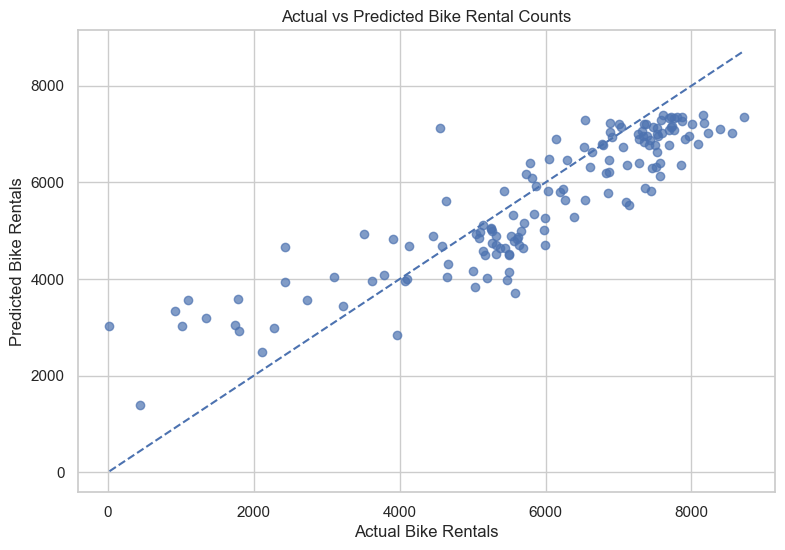

In [53]:
final_predictions = final_model.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rental Counts")
plt.show()

**Insight:**

The residual scatterplot helps identify patterns in prediction errors. Ideally, residuals should be randomly distributed around the zero reference line. Visible patterns or increasing residual spread may indicate non-linearity, changing error variance or areas where the model does not adequately capture rental demand.

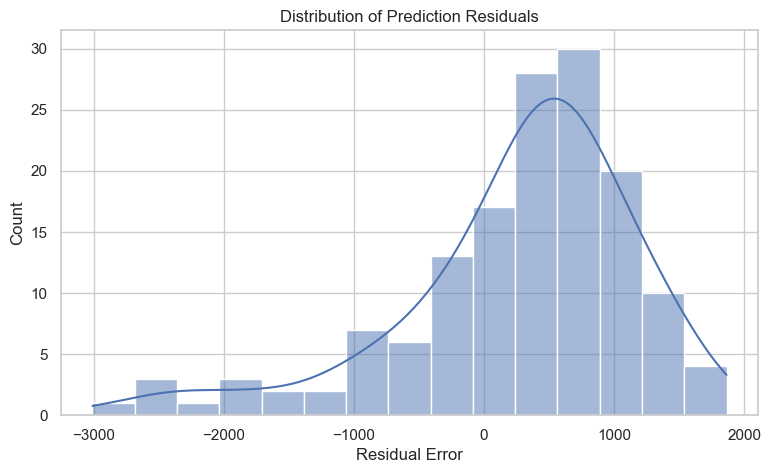

In [54]:
residuals = y_test - final_predictions

plt.figure(figsize=(9, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual Error")
plt.show()

**Insight:**

The residual scatterplot helps identify patterns in prediction errors. Ideally, residuals should be randomly distributed around the zero reference line. Visible patterns or increasing residual spread may indicate non-linearity, changing error variance or areas where the model does not adequately capture rental demand.

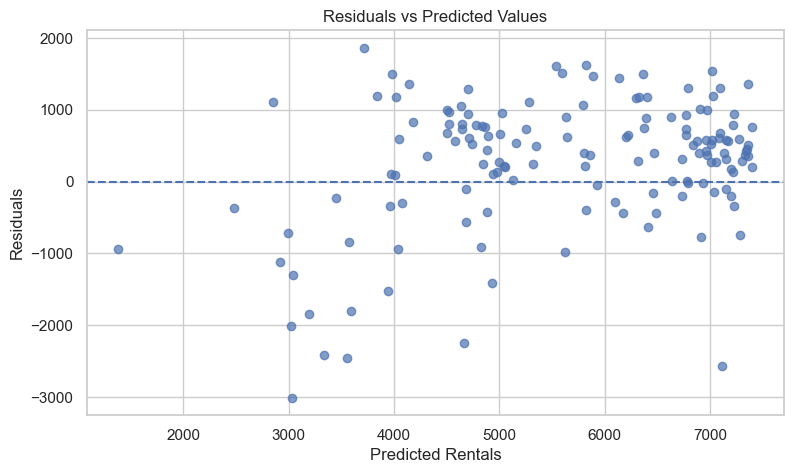

In [55]:
plt.figure(figsize=(9, 5))

plt.scatter(
    final_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(0, linestyle='--')

plt.xlabel("Predicted Rentals")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

**Insight:**

The graph evaluates the predictive performance of the final selected Linear Regression model. Points closer to the diagonal indicate better prediction accuracy. Deviations from the reference line represent differences between actual and predicted rental demand.

,Feature,Importance
8,atemp,467.656954
7,temp,298.871166
9,hum,232.363009
10,windspeed,154.702261
6,weathersit,64.804304
12,day_of_year,47.150300
11,day_of_month,26.924205
4,weekday,22.977223
5,workingday,20.968087
0,season,18.411693


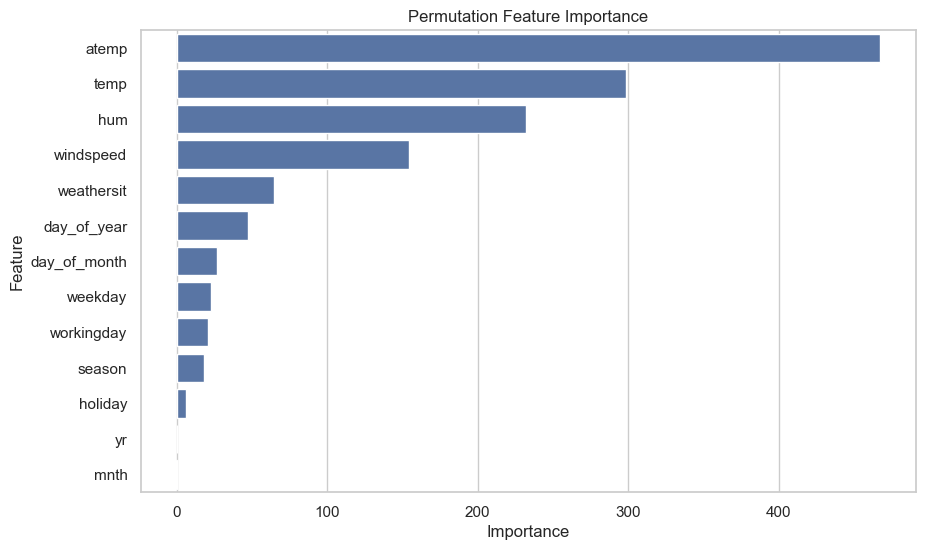

In [56]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_result.importances_mean
}).sort_values('Importance', ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Permutation Feature Importance")
plt.show()

In [57]:
final_candidates = {
    'Linear Regression': model_pipelines['Linear Regression'],
    'Decision Tree': model_pipelines['Decision Tree'],
    'Tuned Random Forest': best_model,
    'Gradient Boosting': model_pipelines['Gradient Boosting']
}

final_cv_results = []

for name, model in final_candidates.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        },
        n_jobs=-1
    )

    final_cv_results.append({
        'Model': name,
        'CV MAE': -scores['test_MAE'].mean(),
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV R2': scores['test_R2'].mean()
    })

final_cv_df = pd.DataFrame(final_cv_results)

display(final_cv_df.sort_values('CV RMSE'))

,Model,CV MAE,CV RMSE,CV R2
0,Linear Regression,959.792707,1174.020588,-0.536016
3,Gradient Boosting,983.777987,1202.242084,-0.676966
2,Tuned Random Forest,1090.111154,1315.371781,-0.845279
1,Decision Tree,1311.410309,1551.312591,-1.493099


In [58]:
selected_name = final_cv_df.sort_values(
    'CV RMSE'
).iloc[0]['Model']

final_model = final_candidates[selected_name]

print("Selected Model:", selected_name)

Selected Model: Linear Regression


In [59]:
final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(
    y_test, final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(
    y_test, final_predictions
)

print("Final Model:", selected_name)
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Model: Linear Regression
MAE: 786.2136513201713
RMSE: 1106.347845660319
R2 Score: 0.651697313354411


**Insight:**

The graph evaluates the predictive performance of the final selected Linear Regression model. Points closer to the diagonal indicate better prediction accuracy. Deviations from the reference line represent differences between actual and predicted rental demand.

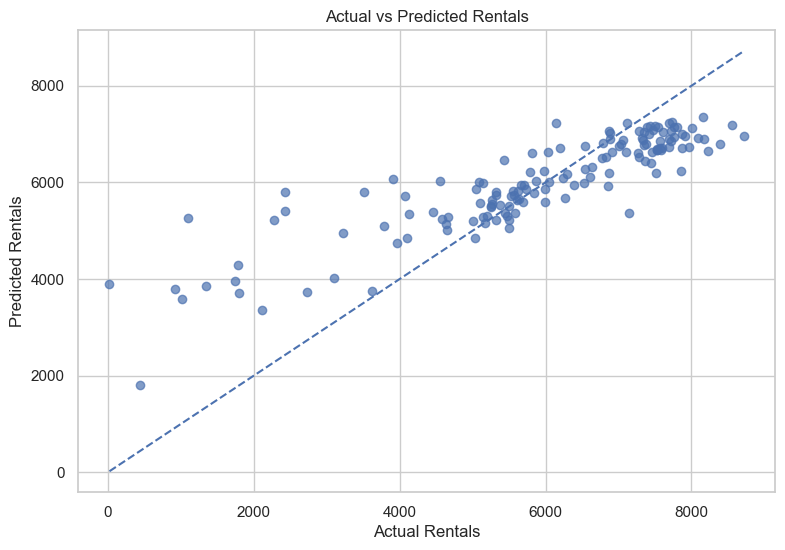

In [60]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, final_predictions, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Rentals")
plt.ylabel("Predicted Rentals")
plt.title("Actual vs Predicted Rentals")
plt.show()

**Insight:**

The residual distribution evaluates the errors produced by the final Linear Regression model. Residuals centered around zero indicate limited systematic bias, while a wider distribution indicates greater variation in prediction errors. This helps assess the reliability of the final model.

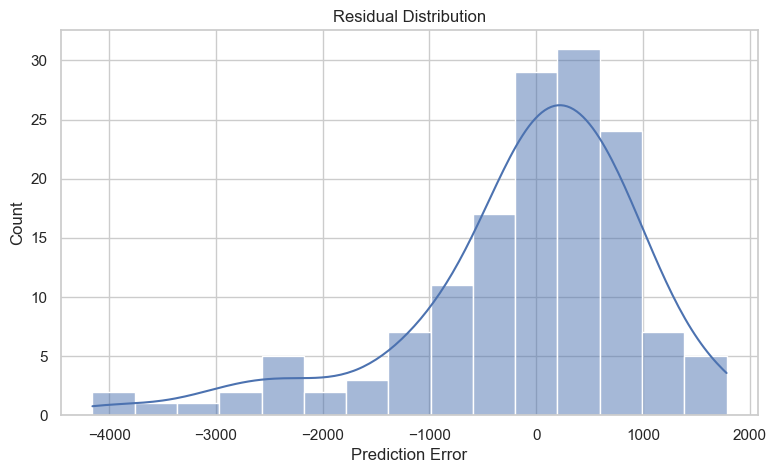

In [61]:
residuals = y_test - final_predictions

plt.figure(figsize=(9, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.show()

**Insight:**

The residual plot examines whether the final model produces random prediction errors. Ideally, the residuals should be scattered around zero without a clear pattern. Any systematic structure may indicate that the Linear Regression model does not capture all the relationships in the dataset.

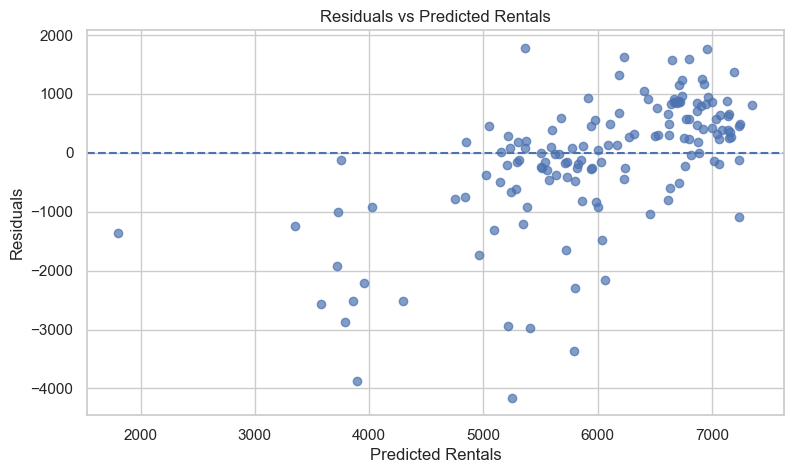

In [62]:
plt.figure(figsize=(9, 5))

plt.scatter(final_predictions, residuals, alpha=0.7)

plt.axhline(0, linestyle='--')

plt.xlabel("Predicted Rentals")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Rentals")
plt.show()

**Insight:**

The permutation importance graph identifies which features have the greatest influence on the final model's predictive performance. It provides an interpretable view of the variables that contribute to daily bike rental predictions. Higher importance values indicate a greater impact on model accuracy.

,Feature,Importance
2,mnth,30608.750308
12,day_of_year,29873.229563
11,day_of_month,5570.725142
8,atemp,363.771122
6,weathersit,160.173310
0,season,139.688981
10,windspeed,61.979377
7,temp,61.685493
9,hum,42.975875
4,weekday,21.334367


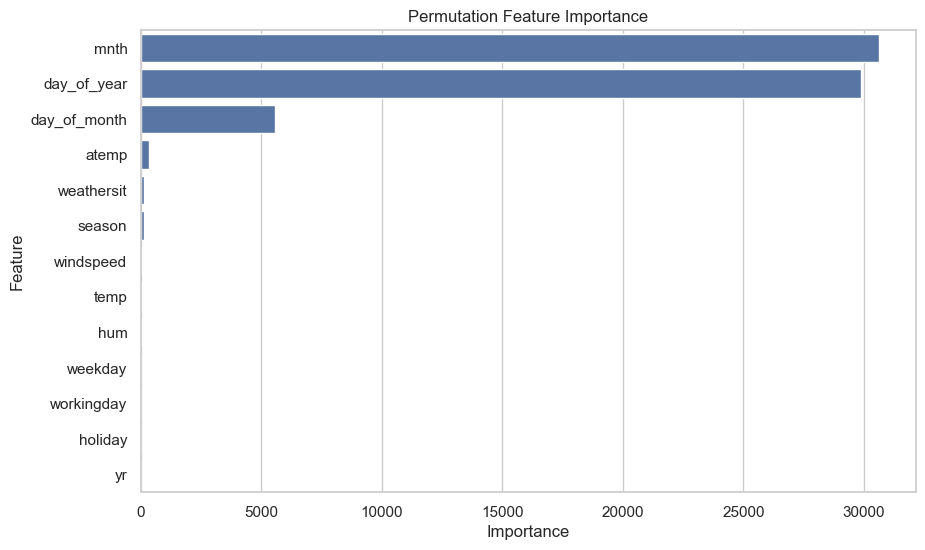

In [63]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean
}).sort_values('Importance', ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Permutation Feature Importance")
plt.show()

In [64]:
test_results = []

for name, model in final_candidates.items():

    predictions = model.predict(X_test)

    test_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        'R2 Score': r2_score(y_test, predictions)
    })

test_results_df = pd.DataFrame(test_results)

print(
    test_results_df.sort_values('RMSE')
)

                 Model          MAE         RMSE  R2 Score
3    Gradient Boosting   757.907685   943.685716  0.746587
0    Linear Regression   786.213651  1106.347846  0.651697
2  Tuned Random Forest   914.606504  1121.329421  0.642200
1        Decision Tree  1265.435374  1635.147981  0.239170


In [65]:
baseline_comparison = pd.DataFrame({
    'Model': ['Baseline', selected_name],
    'MAE': [
        baseline_mae,
        final_mae
    ],
    'RMSE': [
        baseline_rmse,
        final_rmse
    ],
    'R2 Score': [
        baseline_r2,
        final_r2
    ]
})

display(baseline_comparison)

,Model,MAE,RMSE,R2 Score
0,Baseline,2290.412706,2560.555848,-0.865701
1,Linear Regression,786.213651,1106.347846,0.651697


In [66]:
print("PRODUCTION MODEL RECOMMENDATION")

print("Selected Model:", selected_name)

print(f"MAE: {final_mae:.2f}")
print(f"RMSE: {final_rmse:.2f}")
print(f"R2 Score: {final_r2:.4f}")

print("\nRecommendation:")

print(
    f"{selected_name} is the selected candidate based on "
    "its cross-validation RMSE. Its performance should "
    "also be reviewed on the chronological holdout test set "
    "before deployment."
)

PRODUCTION MODEL RECOMMENDATION
Selected Model: Linear Regression
MAE: 786.21
RMSE: 1106.35
R2 Score: 0.6517

Recommendation:
Linear Regression is the selected candidate based on its cross-validation RMSE. Its performance should also be reviewed on the chronological holdout test set before deployment.



# Challenges Faced and Solutions

## 1. Understanding the Dataset
Challenge: The dataset contains both daily and hourly records.

Solution: Used day.csv for the main daily prediction task and hour.csv for additional hourly analysis.

## 2. Feature Selection
Challenge: The dataset contains casual and registered columns that are directly related to the target.

Solution: Excluded these columns to prevent target leakage.

## 3. Feature Encoding
Challenge: Several categorical variables are represented using numerical codes.

Solution: Applied OneHotEncoder through ColumnTransformer.

## 4. Data Validation
Challenge: Random splitting may not represent future prediction performance.

Solution: Used chronological train-test splitting and TimeSeriesSplit cross-validation.

## 5. Model Selection
Challenge: Selecting the best regression algorithm.

Solution: Compared multiple models using MAE, RMSE and R2.

## 6. Hyperparameter Optimization
Challenge: Default model settings may not provide optimal performance.

Solution: Applied RandomizedSearchCV with time-series cross-validation.

## 7. Model Interpretability
Challenge: Understanding which features influence predictions.

Solution: Applied permutation feature importance and residual analysis.



# Final Conclusion

This project involved exploratory data analysis and machine learning-based prediction of daily bike rental demand.

The analysis investigated the relationships between bike rental counts, environmental conditions, seasonal variables and calendar-related information.

Multiple regression algorithms were implemented and compared using MAE, RMSE and R2 Score.

A chronological train-test split and time-series cross-validation were used to evaluate model generalization. Hyperparameter optimization was also performed to improve model performance.

The final candidate model was selected based on validation results and evaluated on unseen test data.

The project demonstrates how historical rental information and environmental variables can support bike demand estimation.

Further improvements could include additional historical data, external validation, weather forecast integration, model monitoring and periodic retraining.


In [68]:
def predict_daily_rentals(
    date,
    season,
    holiday,
    workingday,
    weathersit,
    temp,
    atemp,
    hum,
    windspeed
):

    date = pd.to_datetime(date)

    input_data = pd.DataFrame([{
        'season': season,
        'yr': date.year - 2011,
        'mnth': date.month,
        'holiday': holiday,
        'weekday': date.weekday(),
        'workingday': workingday,
        'weathersit': weathersit,
        'temp': temp,
        'atemp': atemp,
        'hum': hum,
        'windspeed': windspeed,
        'day_of_month': date.day,
        'day_of_year': date.dayofyear
    }])

    prediction = final_model.predict(input_data)[0]

    prediction = max(0, round(prediction))

    print("===== DAILY BIKE RENTAL PREDICTION =====")
    print("Date:", date.date())
    print("Predicted Bike Rentals:", prediction, "bikes")

    return prediction

In [69]:
daily_prediction = predict_daily_rentals(
    date='2012-08-15',
    season=3,
    holiday=0,
    workingday=1,
    weathersit=1,
    temp=0.75,
    atemp=0.70,
    hum=0.50,
    windspeed=0.20
)

===== DAILY BIKE RENTAL PREDICTION =====
Date: 2012-08-15
Predicted Bike Rentals: 7074 bikes
